# **Predicting Booking cancellations at Reservation Time: A Temporal Validation study with leakage control on hotel demand data."**

## Phase 1: Dataset Acquisition, Data Preparation, and Exploratory Data Analysis

**Course:** Data Science Tools and Technologies | **Instructor:** Dr. Asma Ahmed | **TA:** Burhan Hadi Butt

**Team:** Nurmeen Shahid (26L-8010) and Ayesha Mazher (26L-8005)

### Research question
Can information available at reservation time help identify hotel bookings at elevated risk of cancellation?

This notebook covers the pipeline from data acquisition to exploratory analysis. No model is trained or evaluated. Phase 1 has six objectives:

1. Acquire the data and validate its schema.
2. Assess and treat missing values, duplicates, outliers and invalid records.
3. Classify every field by when it becomes known (leakage audit).
4. Engineer features and define three feature sets for Phase 2.
5. Define a chronological split that keeps 2017 as an untouched test period.
6. Characterise cancellation patterns with sample sizes and 95% confidence intervals.

In [1]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import kagglehub
from pathlib import Path
from scipy.stats import chi2_contingency

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.max_colwidth", None)

RANDOM_STATE = 42

In [2]:
def wilson_interval(successes, total, z=1.96):
    """Approximate 95% Wilson confidence interval for a proportion."""
    p = successes / total
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    margin = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / denominator
    return center - margin, center + margin

In [3]:
def cancellation_summary(data, group_column, min_bookings=1, sort=True):
    """Bookings, cancellations, cancellation rate and 95% CI for each group."""
    result = (
        data.groupby(group_column, observed=True)["is_canceled"]
        .agg(bookings="size", cancellations="sum")
        .reset_index()
    )
    result["cancellation_rate"] = result["cancellations"] / result["bookings"]
    result["ci_low"], result["ci_high"] = wilson_interval(result["cancellations"], result["bookings"])
    result = result[result["bookings"] >= min_bookings]
    if sort:
        result = result.sort_values("cancellation_rate", ascending=False)
    return result.reset_index(drop=True)

In [4]:
def plot_rates(summary, column, title):
    """Horizontal bars of cancellation rate with 95% CI; sample size is shown in each label."""
    labels = [f"{value} (n={n:,})" for value, n in zip(summary[column], summary["bookings"])]
    rate = summary["cancellation_rate"]
    plt.figure(figsize=(8, max(3, 0.5 * len(summary) + 1)))
    plt.barh(range(len(summary)), rate, color="steelblue")
    plt.errorbar(rate, range(len(summary)),
                 xerr=[rate - summary["ci_low"], summary["ci_high"] - rate],
                 fmt="none", color="black", capsize=3)
    plt.yticks(range(len(summary)), labels)
    plt.gca().invert_yaxis()
    plt.xlim(0, 1)
    plt.xlabel("Cancellation rate")
    plt.title(title)
    plt.tight_layout()
    plt.show()

## 2. Dataset Loading

**Source.** Hotel Booking Demand dataset (Kaggle: `jessemostipak/hotel-booking-demand`), originally published in Antonio, Almeida and Nunes (2019), "Hotel booking demand datasets", *Data in Brief*, 22, 41–49. Each row is one booking at a city hotel or a resort hotel in Portugal.

**Loading notes.** The CSV stores missing values as the string `NULL`, so `na_values=["NULL"]` converts them to real missing values. The raw data is kept in `df_raw`; all cleaning is done on a copy (`df`). The data has no booking or guest identifier.

In [5]:
# Downloading the latest version

path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")
print("Path to dataset files:", path)

# 'NULL' strings in this CSV are missing values
df_raw = pd.read_csv(Path(path) / "hotel_bookings.csv", na_values=["NULL"])

assert df_raw.shape == (119390, 32)
assert set(df_raw["is_canceled"].unique()) == {0, 1}
print("Rows:", f"{df_raw.shape[0]:,}", "| Columns:", df_raw.shape[1])
df_raw.head()

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
Path to dataset files: /kaggle/input/hotel-booking-demand
Rows: 119,390 | Columns: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 3. Initial Data Exploration

### 3.1 Structure and summary statistics

**What and why.** Data types and distributions are inspected before any change, to decide how each field must be treated.

In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [7]:
display(df_raw.describe().T)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [8]:
display(df_raw.describe(include="object").T)

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


**Observations.**
- The data has 119,390 rows and 32 columns: 16 integer, 4 float and 12 text columns.
- `lead_time` is right-skewed (mean 104 days, median 69, maximum 737).
- `adr` ranges from −6.38 to 5,400, which indicates invalid or extreme values (treated in 4.3).
- `agent` and `company` are numeric identifiers, so they are categorical, not quantities.

### 3.2 Dates and chronological split

Arrival dates are rebuilt from year, month and day. The split follows the proposal: arrivals in 2015–2016 form the train/validation period and all 2017 arrivals form the test period.

In [9]:
df = df_raw.copy()   # df_raw stays untouched; all cleaning is done on df

month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
month_number = {month: number for number, month in enumerate(month_order, start=1)}

df["arrival_date"] = pd.to_datetime(dict(
    year=df["arrival_date_year"],
    month=df["arrival_date_month"].map(month_number),
    day=df["arrival_date_day_of_month"],
))

# Chronological split from the proposal: train/validation = 2015-2016, test = 2017
df["split"] = np.where(df["arrival_date_year"] < 2017, "train_val", "test")

print("Arrival dates:", df["arrival_date"].min().date(), "to", df["arrival_date"].max().date())
print(df["split"].value_counts())
print("\nBookings by arrival month and year:")
display(pd.crosstab(df["arrival_date_month"], df["arrival_date_year"]).reindex(month_order))

Arrival dates: 2015-07-01 to 2017-08-31
split
train_val    78703
test         40687
Name: count, dtype: int64

Bookings by arrival month and year:


arrival_date_year,2015,2016,2017
arrival_date_month,,,
January,0,2248,3681
February,0,3891,4177
March,0,4824,4970
April,0,5428,5661
May,0,5478,6313
June,0,5292,5647
July,2776,4572,5313
August,3889,5063,4925
September,5114,5394,0


**Findings.**
- Arrivals span 1 July 2015 to 31 August 2017.
- Calendar months are not equally covered: July and August appear in three years, January–June in two (2016, 2017) and September–December in two (2015, 2016). Pooled monthly counts therefore overstate July–August, and monthly patterns must be read by year.
- The split gives 78,703 train/validation bookings and 40,687 test bookings. The test period covers January–August only, so test months will be compared with the same months of 2016.

### 3.3 Variable groups
The 32 columns fall into seven groups (definitions follow Antonio et al., 2019).

| Group | Columns | What they describe |
|---|---|---|
| Target | `is_canceled` | 1 = cancelled or no-show, 0 = checked out |
| Booking and timing | `hotel`, `lead_time`, `arrival_date_*` (4 columns) | Which hotel, days booked ahead, arrival date |
| Stay and guests | `stays_in_week_nights`, `stays_in_weekend_nights`, `adults`, `children`, `babies`, `meal` | Length of stay, party size, meal package |
| Guest and channel | `country`, `market_segment`, `distribution_channel`, `customer_type`, `agent`, `company` | Where the booking came from |
| History | `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled` | The guest's earlier bookings |
| Price and policy | `adr`, `deposit_type`, `days_in_waiting_list` | Daily rate, deposit rule, waiting time |
| Room and requests | `reserved_room_type`, `assigned_room_type`, `booking_changes`, `required_car_parking_spaces`, `total_of_special_requests` | Room and extras |
| Outcome (excluded) | `reservation_status`, `reservation_status_date` | Final status; reveals the target, so dropped in Section 7 |

In [10]:
schema = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "unique": df_raw.nunique(),
    "missing": df_raw.isna().sum(),
    "example": df_raw.iloc[0],
})
display(schema)

,dtype,unique,missing,example
hotel,object,2,0,Resort Hotel
is_canceled,int64,2,0,0
lead_time,int64,479,0,342
arrival_date_year,int64,3,0,2015
arrival_date_month,object,12,0,July
arrival_date_week_number,int64,53,0,27
arrival_date_day_of_month,int64,31,0,1
stays_in_weekend_nights,int64,17,0,0
stays_in_week_nights,int64,35,0,0
adults,int64,14,0,2


### 3.4 Distributions and cardinality
**What and why.** Skewness, zero-inflation and the number of categories decide which transformations and encodings Phase 2 needs.

,median,skew,zeros_%,max
babies,0.00,24.65,99.23,10.0
days_in_waiting_list,0.00,11.94,96.90,391.0
previous_cancellations,0.00,24.46,94.57,26.0
required_car_parking_spaces,0.00,4.16,93.79,8.0
children,0.00,4.11,92.80,10.0
booking_changes,0.00,6.00,84.86,21.0
total_of_special_requests,0.00,1.35,58.90,5.0
stays_in_weekend_nights,1.00,1.38,43.55,19.0
stays_in_week_nights,2.00,2.86,6.40,50.0
lead_time,69.00,1.35,5.31,737.0


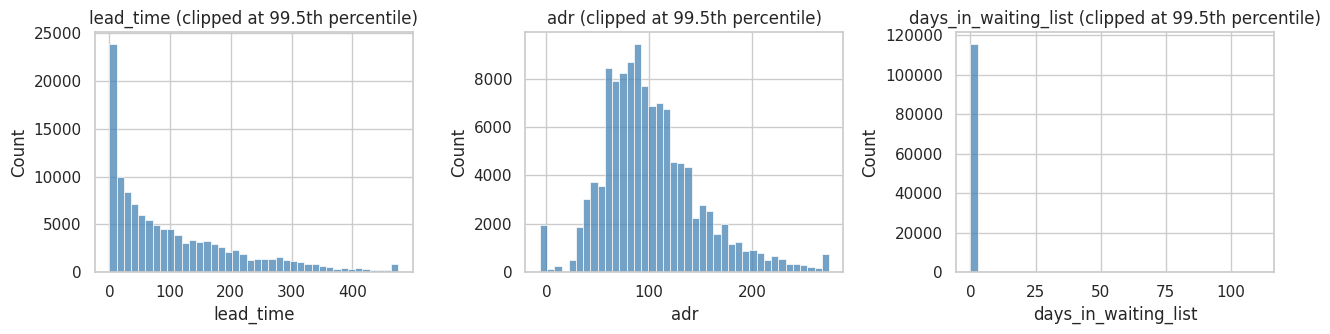

Distinct values: {'country': 177, 'agent': 333, 'company': 352, 'market_segment': 8, 'reserved_room_type': 10}


In [11]:
num_cols = ["lead_time", "adr", "stays_in_week_nights", "stays_in_weekend_nights", "adults",
            "children", "babies", "previous_cancellations", "booking_changes",
            "days_in_waiting_list", "required_car_parking_spaces", "total_of_special_requests"]

profile = pd.DataFrame({
    "median": df_raw[num_cols].median(),
    "skew": df_raw[num_cols].skew(),
    "zeros_%": (df_raw[num_cols] == 0).mean() * 100,
    "max": df_raw[num_cols].max(),
}).round(2)
display(profile.sort_values("zeros_%", ascending=False))

# Only the three fields where the shape drives a Phase 2 decision
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, c in zip(axes, ["lead_time", "adr", "days_in_waiting_list"]):
    s = df_raw[c]
    sns.histplot(s.clip(upper=s.quantile(0.995)), bins=40, ax=ax, color="steelblue")
    ax.set_title(f"{c} (clipped at 99.5th percentile)")
plt.tight_layout(); plt.show()

print("Distinct values:", df_raw[["country", "agent", "company", "market_segment", "reserved_room_type"]].nunique().to_dict())

**Observations.**
- **Zero-inflated:** `babies` (99.2% zeros), `days_in_waiting_list` (96.9%), `previous_cancellations` (94.6%), `required_car_parking_spaces` (93.8%), `children` (92.8%) and `booking_changes` (84.9%). Special requests are 58.9% zeros.
- **Right-skewed:** `lead_time` (skew 1.35, median 69 days). `adr` (skew 10.5) and `adults` (18.3) are inflated by a few extreme values (ADR 5,400; 55 adults), which is why they are treated in 4.3. `days_in_waiting_list` (skew 11.9) is also heavy-tailed, so log1p is applied to `lead_time`, `adr` and `days_in_waiting_list` in Phase 2.
- **Cardinality:** `country` has 177 values, `agent` 333 and `company` 352, so they are grouped (`country`) or reduced to flags (`agent`, `company`) instead of being fully one-hot encoded. `market_segment` (8) and `reserved_room_type` (10) are low-cardinality.

## 4. Data Cleaning

### 4.1 Missing values

**What and why.** Missing values are counted per field. The treatment depends on what missingness means for each field.

,missing_count,missing_percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


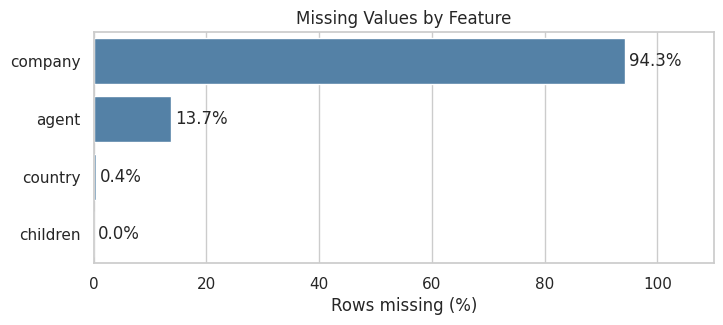

In [12]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100,
})
missing_summary = missing_summary[missing_summary["missing_count"] > 0].sort_values(
    "missing_percent", ascending=False)
display(missing_summary.round(2))

plt.figure(figsize=(8, 3))
ax = sns.barplot(x=missing_summary["missing_percent"], y=missing_summary.index, color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.title("Missing Values by Feature")
plt.xlabel("Rows missing (%)")
plt.ylabel("")
plt.xlim(0, 110)
plt.show()

**Findings and treatment.**

| Field | Missing | Treatment | Rationale |
|---|---|---|---|
| `company` | 112,593 (94.31%) | Filled with 0 ("no company recorded") | Missing most likely means no company was involved |
| `agent` | 16,340 (13.69%) | Filled with 0 ("no agent recorded") | Same rationale |
| `country` | 488 (0.41%) | "Unknown" category | Too few rows to justify imputation |
| `children` | 4 (<0.01%) | Filled with 0 | Most bookings have no children (median 0) |

None of these treatments uses a statistic computed from the data, so none can leak information across the train/test boundary. `agent` and `company` are later treated as categorical identifiers, so 0 acts as a "none" category.

In [13]:
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")
df["agent"] = df["agent"].fillna(0)      # 0 = no agent recorded
df["company"] = df["company"].fillna(0)  # 0 = no company recorded

cols = ["children", "country", "agent", "company"]
assert df[cols].isna().sum().sum() == 0
print("Missing values after handling:\n", df[cols].isna().sum())

Missing values after handling:
 children    0
country     0
agent       0
company     0
dtype: int64


### 4.2 Duplicate records

**What and why.** Exact duplicate rows are counted, and their effect on the cancellation rate is measured, because duplicates can bias both the rate and any model evaluation.

In [14]:
duplicate_mask = df_raw.duplicated()
print(f"Exact duplicate rows: {duplicate_mask.sum():,} ({duplicate_mask.mean():.2%})")

duplicate_sensitivity = pd.DataFrame({
    "version": ["All rows retained", "One row per exact pattern", "Duplicate rows only"],
    "rows": [len(df_raw), (~duplicate_mask).sum(), duplicate_mask.sum()],
    "cancellation_rate_percent": [
        df_raw["is_canceled"].mean() * 100,
        df_raw.loc[~duplicate_mask, "is_canceled"].mean() * 100,
        df_raw.loc[duplicate_mask, "is_canceled"].mean() * 100,
    ],
}).round(2)
display(duplicate_sensitivity)

Exact duplicate rows: 31,994 (26.80%)


,version,rows,cancellation_rate_percent
0,All rows retained,119390,37.04
1,One row per exact pattern,87396,27.49
2,Duplicate rows only,31994,63.13


**Findings.** 31,994 rows (26.80%) are exact duplicates. Keeping one row per pattern leaves 87,396 rows and lowers the cancellation rate from 37.04% to 27.49%, so the duplicated rows are disproportionately cancelled bookings.

**Decision: all rows are retained.** Without a booking identifier, identical rows may be separate bookings with the same attributes (for example, agent or group bookings), and removing them could discard real reservations. Duplicates share an arrival date, so they cannot straddle the train/test boundary. Phase 2 reports results on both the full data and the one-row-per-pattern data.


In [15]:
dup = df_raw[duplicate_mask]
composition = pd.DataFrame({
    "duplicates_%": dup["market_segment"].value_counts(normalize=True) * 100,
    "all_rows_%": df_raw["market_segment"].value_counts(normalize=True) * 100,
}).round(1)
display(composition)
print(dup["hotel"].value_counts(normalize=True).round(3))

,duplicates_%,all_rows_%
market_segment,,
Aviation,0.0,0.2
Complementary,0.1,0.6
Corporate,3.4,4.4
Direct,2.5,10.6
Groups,46.5,16.6
Offline TA/TO,32.3,20.3
Online TA,15.2,47.3
Undefined,NaN,0.0


hotel
City Hotel      0.81
Resort Hotel    0.19
Name: proportion, dtype: float64


The duplicates are concentrated in specific booking types: Groups make up 46.5% of duplicate rows but only 16.6% of all rows, Offline TA/TO 32.3% against 20.3%, and the City Hotel 81% against 66% of all rows. Online TA is under-represented (15.2% against 47.3%).

This fits repeated, identical group or agent reservations rather than accidental copies, but without a booking identifier it cannot be proven.

### 4.3 Outliers and invalid values

**What and why.** Extreme values are screened with 1.5 × IQR fences and boxplots, and invalid values are counted. Decisions rest on plausibility, not on the fences alone.

,Feature,Min,Max,Lower Fence,Upper Fence,Outlier Count,Outlier %
0,lead_time,0.00,737.0,-195.00,373.00,3005,2.52
1,adr,-6.38,5400.0,-15.77,211.06,3793,3.18
2,adults,0.00,55.0,2.00,2.00,29710,24.88
3,stays_in_week_nights,0.00,50.0,-2.00,6.00,3354,2.81
4,stays_in_weekend_nights,0.00,19.0,-3.00,5.00,265,0.22
5,days_in_waiting_list,0.00,391.0,0.00,0.00,3698,3.10


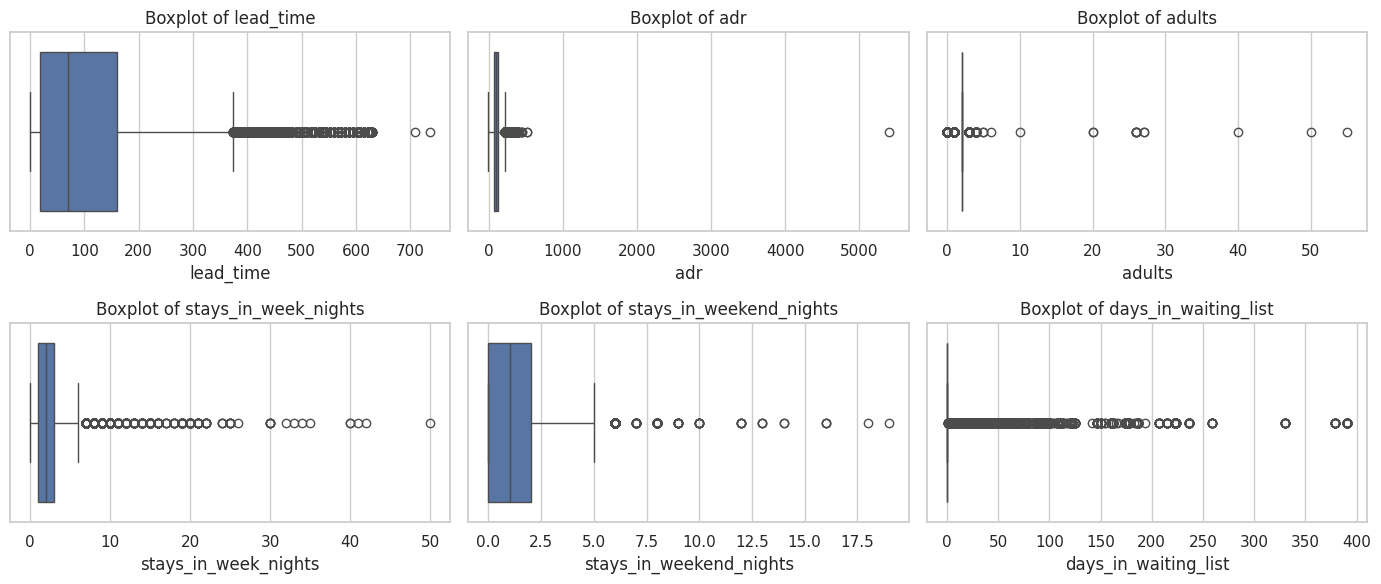

Negative ADR values: 1
ADR values above 1,000: 1
Bookings with zero guests: 180
Bookings with zero nights: 715


In [16]:
outlier_columns = ["lead_time", "adr", "adults", "stays_in_week_nights",
                   "stays_in_weekend_nights", "days_in_waiting_list"]

rows = []
for col in outlier_columns:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append([col, df[col].min(), df[col].max(), lo, hi, n, n / len(df) * 100])

display(pd.DataFrame(rows, columns=["Feature", "Min", "Max", "Lower Fence", "Upper Fence",
                                    "Outlier Count", "Outlier %"]).round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, col in zip(axes.ravel(), outlier_columns):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

print("Negative ADR values:", (df["adr"] < 0).sum())
print("ADR values above 1,000:", (df["adr"] > 1000).sum())
print("Bookings with zero guests:", ((df["adults"] + df["children"] + df["babies"]) == 0).sum())
print("Bookings with zero nights:", ((df["stays_in_week_nights"] + df["stays_in_weekend_nights"]) == 0).sum())

**Findings and decisions.**
- **`lead_time`:** maximum 737 days; 3,005 bookings (2.52%) lie above the upper fence of 373 days. Long advance bookings are plausible, so all are retained.
- **`adults`, `stays_in_week_nights`, `days_in_waiting_list`:** maxima of 55, 50 and 391. These are rare values consistent with group bookings or long stays, not clear errors, and are retained.
- **IQR limitation:** `adults` and `days_in_waiting_list` have an interquartile range of 0, so their fences collapse (29,710 and 3,698 values "outside"). For these fields the maximum is more informative than the fence count.
- **adr**: one negative value (-6.38) and one clear error (5,400; the next largest is 510). The negative value is replaced by the 2015-2016 median. All values above the 2015-2016 99.9th percentile (305) are capped; this also trims a small number of plausible high prices, counted above. The cap is learned on 2015-2016 only.
- **Zero guests (180) and zero nights (715):** counted and retained; Phase 2 tests sensitivity to them.

No rows are removed, so the target distribution is unchanged.

In [17]:
train = df["split"] == "train_val"     # thresholds are learned on 2015-2016 only

# Impossible negative price -> median of valid training-period prices
df.loc[df["adr"] < 0, "adr"] = df.loc[train & (df["adr"] >= 0), "adr"].median()

# Extreme prices -> capped at the 99.9th percentile of the training period
adr_cap = df.loc[train, "adr"].quantile(0.999)
print("ADR max before capping:", df["adr"].max())
n_clip_train = int(((df["adr"] > adr_cap) & train).sum())
n_clip_test = int(((df["adr"] > adr_cap) & ~train).sum())
print(f"Rows above the cap: {n_clip_train} in 2015-2016, {n_clip_test} in 2017")
df["adr"] = df["adr"].clip(upper=adr_cap)
print("ADR cap (99.9th percentile, 2015-2016):", round(adr_cap, 2), "| max after capping:", round(df["adr"].max(), 2))

assert df["adr"].min() >= 0 and df["adr"].isna().sum() == 0
assert len(df) == len(df_raw)      # no rows removed

ADR max before capping: 5400.0
Rows above the cap: 67 in 2015-2016, 165 in 2017
ADR cap (99.9th percentile, 2015-2016): 305.0 | max after capping: 305.0


### 4.4 Categorical consistency
**What and why.** The proposal flags inconsistent categorical values as a risk. Labels are checked for spacing, placeholder values and duplicate meanings.

In [18]:
cat_check = ["hotel","meal","country","market_segment","distribution_channel",
             "reserved_room_type","assigned_room_type","deposit_type","customer_type","reservation_status"]
for c in cat_check:
    s = df[c].astype(str)
    assert (s == s.str.strip()).all(), f"whitespace in {c}"
    if c != "country":
        print(c, sorted(s.unique()))
print("Undefined counts:", {c: int((df[c] == "Undefined").sum()) for c in cat_check})
print("Country code lengths:", df["country"].str.len().value_counts().to_dict())

# 'SC' and 'Undefined' both mean "no meal package" in the dataset documentation
df["meal"] = df["meal"].replace({"Undefined": "SC"})
print("meal after merge:", sorted(df["meal"].unique()))

hotel ['City Hotel', 'Resort Hotel']
meal ['BB', 'FB', 'HB', 'SC', 'Undefined']
market_segment ['Aviation', 'Complementary', 'Corporate', 'Direct', 'Groups', 'Offline TA/TO', 'Online TA', 'Undefined']
distribution_channel ['Corporate', 'Direct', 'GDS', 'TA/TO', 'Undefined']
reserved_room_type ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'L', 'P']
assigned_room_type ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'P']
deposit_type ['No Deposit', 'Non Refund', 'Refundable']
customer_type ['Contract', 'Group', 'Transient', 'Transient-Party']
reservation_status ['Canceled', 'Check-Out', 'No-Show']
Undefined counts: {'hotel': 0, 'meal': 1169, 'country': 0, 'market_segment': 2, 'distribution_channel': 5, 'reserved_room_type': 0, 'assigned_room_type': 0, 'deposit_type': 0, 'customer_type': 0, 'reservation_status': 0}
Country code lengths: {3: 117623, 2: 1279, 7: 488}
meal after merge: ['BB', 'FB', 'HB', 'SC']


**Findings and decision.** No whitespace problems were found. `meal` has two labels for "no package": SC and Undefined (1,169 rows), which are merged into SC.
`market_segment` has 2 "Undefined" rows and `distribution_channel` has 5, which are kept as their own level and hidden by the minimum-bookings filter. `country` has inconsistent code lengths: 117,623 three-letter codes, 1,279 two-letter codes, and 488 seven-character values ("Unknown", from the missing-value fill).

## 5. Data Preprocessing

**What and why.** Only transformations that use no statistic from the evaluation period are applied: arrival month becomes an ordered category, and count-like and identifier columns stored as floats become integers. Imputation, encoding and scaling are deferred to Phase 2 and will be fitted inside training folds only.

In [19]:
df["arrival_date_month"] = pd.Categorical(df["arrival_date_month"], categories=month_order, ordered=True)

# Count-like and identifier columns stored as floats become integers
for col in ["children", "agent", "company"]:
    df[col] = df[col].astype(int)

display(df[["arrival_date_month", "children", "agent", "company", "is_canceled", "split"]].dtypes.to_frame("dtype"))
display(df.groupby(["split", "hotel"]).agg(bookings=("is_canceled", "size"),
                                           cancellation_rate=("is_canceled", "mean")).round(3))

,dtype
arrival_date_month,category
children,int64
agent,int64
company,int64
is_canceled,int64
split,object


bookings  cancellation_rate
split     hotel                                    
test      City Hotel       27508              0.425
          Resort Hotel     13179              0.308
train_val City Hotel       51822              0.413
          Resort Hotel     26881              0.263

**Scope of this section.** This section converts types and ordering only. The pipeline that imputes, log-transforms, scales and encodes is defined in Section 7.3. It is fitted on the 2015-2016 period only and applied to 2017 without refitting.

## 6. Feature Engineering

**What and why.** New variables summarise booking behaviour more directly than the raw fields. Every threshold is learned on 2015-2016 only.

| Feature | Definition | Rationale |
|---|---|---|
| `total_nights` | Week nights + weekend nights | Overall stay length |
| `total_guests` | Adults + children + babies | Party size |
| `is_family` | 1 if children or babies are present | Family travel behaviour |
| `weekend_stay` | 1 if at least one weekend night | Leisure versus business pattern |
| `is_domestic` | 1 if country is PRT | Portuguese guests are the largest market (see 8.9) |
| `high_adr` | 1 if ADR exceeds the 2015-2016 75th percentile | Price tier |
| `lead_time_group` | 0-7, 8-30, 31-90, 91-180, 181-365, >365 days | Captures a non-linear lead-time effect in interpretable groups |
| `has_agent`, `has_company` | 1 if an agent or company ID is recorded | Keeps the signal without high-cardinality IDs |
| `was_waitlisted`, `has_previous_cancel` | Waiting-list days > 0; previous cancellations > 0 | Captures sparse, zero-inflated counts |
| `arrival_weekday` | Day of week of arrival | Weekday versus weekend arrival behaviour |
| `nights_group`, `booking_changes_group` | Binned total nights and booking changes | Interpretable EDA groups |

In [20]:

df["total_nights"] = df["stays_in_week_nights"] + df["stays_in_weekend_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
df["is_family"] = ((df["children"] > 0) | (df["babies"] > 0)).astype(int)
df["weekend_stay"] = (df["stays_in_weekend_nights"] > 0).astype(int)
df["is_domestic"] = (df["country"] == "PRT").astype(int)

adr_q75 = df.loc[train, "adr"].quantile(0.75)    # threshold from 2015-2016 only
df["high_adr"] = (df["adr"] > adr_q75).astype(int)

df["lead_time_group"] = pd.cut(
    df["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, np.inf],
    labels=["0-7 days", "8-30 days", "31-90 days", "91-180 days", "181-365 days", ">365 days"],
)


df["has_agent"] = (df["agent"] > 0).astype(int)                  # agent was filled with 0 = no agent
df["has_company"] = (df["company"] > 0).astype(int)              # company was filled with 0 = no company
df["was_waitlisted"] = (df["days_in_waiting_list"] > 0).astype(int)
df["has_previous_cancel"] = (df["previous_cancellations"] > 0).astype(int)

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["arrival_weekday"] = pd.Categorical(df["arrival_date"].dt.day_name(),
                                       categories=weekday_order, ordered=True)

df["nights_group"] = pd.cut(df["total_nights"], [-1, 0, 1, 3, 7, 14, np.inf],
                            labels=["0", "1", "2-3", "4-7", "8-14", "15+"])
df["booking_changes_group"] = pd.cut(df["booking_changes"], [-1, 0, 1, 2, np.inf],
                                     labels=["0", "1", "2", "3+"])

# --- Validation of the engineered features ---
assert (df["total_nights"] == df["stays_in_week_nights"] + df["stays_in_weekend_nights"]).all()
assert (df["total_guests"] == df["adults"] + df["children"] + df["babies"]).all()
assert (df["is_family"] == ((df["children"] > 0) | (df["babies"] > 0)).astype(int)).all()
assert (df["weekend_stay"] == (df["stays_in_weekend_nights"] > 0).astype(int)).all()
assert df["lead_time_group"].notna().all()
assert (df["has_agent"] == (df["agent"] > 0).astype(int)).all()
assert (df["has_company"] == (df["company"] > 0).astype(int)).all()
assert df[["arrival_weekday", "nights_group", "booking_changes_group"]].notna().all().all()
print("All feature checks passed. ADR 75th percentile (2015-2016):", adr_q75)

display(df[["total_nights", "total_guests", "is_family", "weekend_stay", "is_domestic",
            "high_adr", "has_agent", "has_company", "was_waitlisted", "has_previous_cancel"]]
        .describe().T.round(3))

All feature checks passed. ADR 75th percentile (2015-2016): 117.3


,count,mean,std,min,25%,50%,75%,max
total_nights,119390.0,3.428,2.557,0.0,2.0,3.0,4.0,69.0
total_guests,119390.0,1.968,0.722,0.0,2.0,2.0,2.0,55.0
is_family,119390.0,0.078,0.268,0.0,0.0,0.0,0.0,1.0
weekend_stay,119390.0,0.564,0.496,0.0,0.0,1.0,1.0,1.0
is_domestic,119390.0,0.407,0.491,0.0,0.0,0.0,1.0,1.0
high_adr,119390.0,0.304,0.460,0.0,0.0,0.0,1.0,1.0
has_agent,119390.0,0.863,0.344,0.0,1.0,1.0,1.0,1.0
has_company,119390.0,0.057,0.232,0.0,0.0,0.0,0.0,1.0
was_waitlisted,119390.0,0.031,0.173,0.0,0.0,0.0,0.0,1.0
has_previous_cancel,119390.0,0.054,0.227,0.0,0.0,0.0,0.0,1.0


**Observations.** The average stay is 3.43 nights (maximum 69). 86.3% of bookings come through an agent, but only 5.7% involve a company. 3.1% were waitlisted and 5.4% have a previous cancellation. 7.8% are family bookings, 56.4% include a weekend night and 40.7% are Portuguese. The proportion above the historical threshold increased; this may reflect price changes or booking-mix changes.

## 7. Feature Selection: Leakage Audit

### 7.1 Timing audit
**What and why.** The prediction is made when a reservation is created, so a variable is usable only if its value is known at that moment. Each field is classified as a candidate, ambiguous (may be recorded or updated after booking) or excluded (reveals or follows the outcome). Selection follows this timing rule, not model performance, so it cannot use the test period.

In [21]:
feature_timing_audit = pd.DataFrame(
    [
        ["hotel, lead_time, arrival date fields, stay length, guests, market_segment, customer_type, previous bookings", "Known at reservation", "Candidate predictors"],
        ["reserved_room_type, meal, country, distribution_channel, agent, company", "Known at reservation", "Candidate predictors"],
        ["adr", "Lodging revenue per night; can be updated during the stay", "Candidate; test with and without"],
        ["deposit_type", "Known at booking; Non Refund pattern needs a definition check", "Candidate; test with and without"],
        ["booking_changes", "Accumulates until check-in or cancellation", "Ambiguous"],
        ["days_in_waiting_list", "Accumulates after the booking is entered", "Ambiguous"],
        ["required_car_parking_spaces", "No cancelled booking requires parking; likely recorded at or after arrival", "Ambiguous"],
        ["total_of_special_requests", "Can be added after the booking is made", "Ambiguous"],
        ["assigned_room_type", "Can change up to check-in", "Excluded"],
        ["reservation_status", "Final status; reveals the outcome", "Excluded"],
        ["reservation_status_date", "Recorded after the outcome", "Excluded"],
        ["is_canceled", "Final outcome", "Target"],
        ["arrival_date_year", "Defines the chronological split", "Not a predictor"],
    ],
    columns=["feature", "timing", "decision"],
)
display(feature_timing_audit)

# Does reservation_status reproduce the target?
display(pd.crosstab(df_raw["reservation_status"], df_raw["is_canceled"]))

,feature,timing,decision
0,"hotel, lead_time, arrival date fields, stay length, guests, market_segment, customer_type, previous bookings",Known at reservation,Candidate predictors
1,"reserved_room_type, meal, country, distribution_channel, agent, company",Known at reservation,Candidate predictors
2,adr,Lodging revenue per night; can be updated during the stay,Candidate; test with and without
3,deposit_type,Known at booking; Non Refund pattern needs a definition check,Candidate; test with and without
4,booking_changes,Accumulates until check-in or cancellation,Ambiguous
5,days_in_waiting_list,Accumulates after the booking is entered,Ambiguous
6,required_car_parking_spaces,No cancelled booking requires parking; likely recorded at or after arrival,Ambiguous
7,total_of_special_requests,Can be added after the booking is made,Ambiguous
8,assigned_room_type,Can change up to check-in,Excluded
9,reservation_status,Final status; reveals the outcome,Excluded


is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


**Findings.** Each value of `reservation_status` maps to a single value of `is_canceled` (crosstab above), so using it would reproduce the target. It is excluded together with `reservation_status_date` and `assigned_room_type`. Of the 44,224 rows with `is_canceled` = 1, 43,017 are "Canceled" and 1,207 are "No-Show", so the target counts no-shows as cancellations. Four fields (`booking_changes`, `days_in_waiting_list`, `required_car_parking_spaces`, `total_of_special_requests`) may be recorded after booking. `adr` accumulates from lodging transactions. These fields are kept for analysis and tested separately in Phase 2. The original columns remain in `df_raw`, so Phase 2 can measure the effect of leakage (research question 1) with a deliberately leaky feature set.

In [22]:
leakage_features = ["reservation_status", "reservation_status_date", "assigned_room_type"]
ambiguous_features = ["booking_changes", "days_in_waiting_list",
                      "required_car_parking_spaces", "total_of_special_requests"]

df = df.drop(columns=leakage_features, errors="ignore")   # df_raw still holds them for the Phase 2 leakage comparison
assert not set(leakage_features) & set(df.columns)
print("Leakage columns removed. New shape:", df.shape)
print("Ambiguous (kept for EDA, tested separately in Phase 2):", ambiguous_features)

Leakage columns removed. New shape: (119390, 45)
Ambiguous (kept for EDA, tested separately in Phase 2): ['booking_changes', 'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests']


### 7.2 Feature selection and the three feature sets
**What and why.** Selection follows the timing rule from the audit, plus redundancy. Three sets let Phase 2 measure how much apparent performance comes from non-reservation-time fields (research question 1).

| Dropped from all sets | Reason |
|---|---|
| `arrival_date_week_number`, `arrival_date_day_of_month` | Redundant with arrival month and weekday; the day of month has no expected signal |
| `stays_in_week_nights`, `stays_in_weekend_nights` | Exact components of `total_nights`; `weekend_stay` keeps the weekend information |
| `adults`, `children`, `babies` | Captured by `total_guests` and `is_family` |
| `is_domestic`, `high_adr`, `lead_time_group` | Redundant with the country one-hot, `adr` and `lead_time` (kept for EDA only) |
| `agent`, `company` | Identifiers replaced by `has_agent` and `has_company` |
| `arrival_date_year`, `arrival_date`, `split` | Define the split; not predictors |

In [23]:
NUM_STRICT = ["lead_time", "adr", "total_nights", "total_guests",
              "previous_cancellations", "previous_bookings_not_canceled"]
BIN_STRICT = ["is_repeated_guest", "is_family", "weekend_stay", "has_agent", "has_company"]
CAT_STRICT = ["hotel", "arrival_date_month", "arrival_weekday", "meal", "country",
              "market_segment", "distribution_channel", "reserved_room_type", "customer_type"]
AMBIGUOUS = ["booking_changes", "days_in_waiting_list",
             "required_car_parking_spaces", "total_of_special_requests"]
LEAKY_CAT = ["assigned_room_type", "reservation_status"]     # still held in df_raw
DEPOSIT_OPTION = ["deposit_type"]                            # added in Phase 2 to test with and without

feature_sets = {
    "A_strict":                {"num": NUM_STRICT, "bin": BIN_STRICT, "cat": CAT_STRICT},
    "B_strict_plus_ambiguous": {"num": NUM_STRICT + AMBIGUOUS, "bin": BIN_STRICT, "cat": CAT_STRICT},
    "C_leaky_benchmark":       {"num": NUM_STRICT + AMBIGUOUS, "bin": BIN_STRICT, "cat": CAT_STRICT + LEAKY_CAT},
}

model_frame = df.join(df_raw[LEAKY_CAT])                     # same index as df_raw
for name, s in feature_sets.items():
    missing = [c for g in s.values() for c in g if c not in model_frame.columns]
    assert not missing, (name, missing)

train_df = model_frame[model_frame["split"] == "train_val"]
test_df = model_frame[model_frame["split"] == "test"]

display(pd.DataFrame({
    "feature_set": list(feature_sets),
    "n_columns": [sum(len(g) for g in s.values()) for s in feature_sets.values()],
    "purpose": ["Honest reservation-time model (headline result)",
                "Tests whether post-booking fields inflate performance",
                "Deliberately leaky benchmark to quantify the leakage effect (RQ1)"],
}))

,feature_set,n_columns,purpose
0,A_strict,20,Honest reservation-time model (headline result)
1,B_strict_plus_ambiguous,24,Tests whether post-booking fields inflate performance
2,C_leaky_benchmark,26,Deliberately leaky benchmark to quantify the leakage effect (RQ1)


### 7.3 Leakage-safe preprocessing pipeline
**What and why.** Imputation, log transformation, scaling and encoding are defined as one pipeline. It is fitted on the 2015-2016 period only and applied to 2017 with `transform`, so no test statistic is used. The 2017 transform here only checks that the pipeline runs; no evaluation is done in Phase 1.

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer

def make_preprocessor(num_cols, bin_cols, cat_cols):
    log_cols = [c for c in ("lead_time", "adr", "days_in_waiting_list") if c in num_cols]   # right-skewed
    plain = [c for c in num_cols if c not in log_cols]
    return ColumnTransformer([
        ("log_scale", Pipeline([("imp", SimpleImputer(strategy="median")),
                                ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                ("sc", StandardScaler())]), log_cols),
        ("scale", Pipeline([("imp", SimpleImputer(strategy="median")),
                            ("sc", StandardScaler())]), plain),
        ("bin", "passthrough", bin_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=False), cat_cols),
    ])

for name, s in feature_sets.items():
    cols = s["num"] + s["bin"] + s["cat"]
    pre = make_preprocessor(s["num"], s["bin"], s["cat"])
    Xtr = pre.fit_transform(train_df[cols])     # fitted on 2015-2016 only
    Xte = pre.transform(test_df[cols])          # transform only
    assert not np.isnan(Xtr).any() and not np.isnan(Xte).any()
    print(f"{name}: train {Xtr.shape}, test {Xte.shape}")

A_strict: train (78703, 96), test (40687, 96)
B_strict_plus_ambiguous: train (78703, 100), test (40687, 100)
C_leaky_benchmark: train (78703, 114), test (40687, 114)


**Result.** The pipeline runs on all three sets: 96 features for A (strict), 100 for B (adds four ambiguous fields) and 114 for C (adds the leaky fields), with no missing values after transformation. Train and test have identical columns.

## 8. Exploratory Data Analysis

Rates are reported with the number of bookings (n). Group tables and bar charts carry 95% Wilson intervals; the monthly line chart and the heatmaps show rates without intervals, but heatmap cells show n and are suppressed below 50. The intervals treat bookings as independent, which is optimistic because duplicate rows and group bookings are correlated. Descriptive plots in this section use all arrivals, including 2017, to describe drift. Association and feature-selection analyses (8.11) use the 2015-2016 period only, so 2017 stays untouched for model development.

### 8.1 Cancellation distribution

,bookings,percent
is_canceled,,
0,75166,62.96
1,44224,37.04


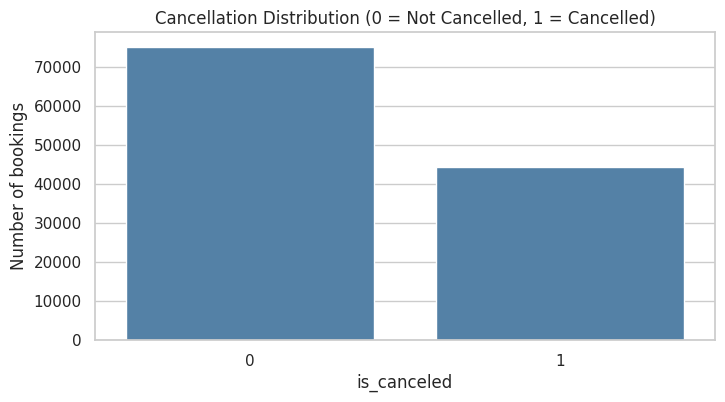

In [25]:
target_summary = df["is_canceled"].value_counts().sort_index().to_frame("bookings")
target_summary["percent"] = target_summary["bookings"] / len(df) * 100
display(target_summary.round(2))

sns.countplot(x="is_canceled", data=df, color="steelblue")
plt.title("Cancellation Distribution (0 = Not Cancelled, 1 = Cancelled)")
plt.ylabel("Number of bookings")
plt.show()

**Finding.** 44,224 of 119,390 bookings (37.04%) are cancelled, including 1,207 no-shows, and 75,166 (62.96%) are not. The imbalance is moderate.

Hence, Accuracy is a poor metric here, because always predicting "not cancelled" would score 62.96%, so Average Precision (PR-AUC) is the primary Phase 2 metric, as in the proposal.

### 8.2 Cancellation by hotel

,hotel,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,City Hotel,79330,33102,0.417,0.414,0.421
1,Resort Hotel,40060,11122,0.278,0.273,0.282


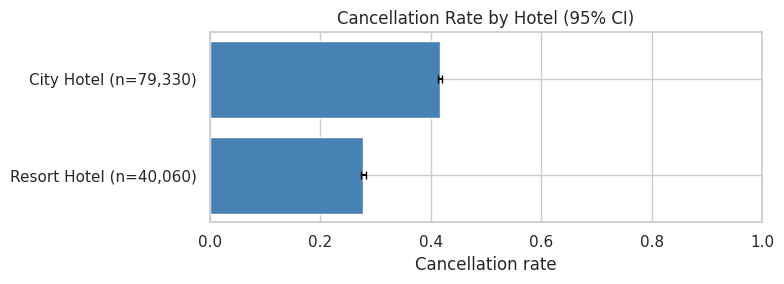

In [26]:
hotel_rates = cancellation_summary(df, "hotel")
display(hotel_rates.round(3))
plot_rates(hotel_rates, "hotel", "Cancellation Rate by Hotel (95% CI)")

**Finding.** The City Hotel cancels 41.7% of bookings (33,102 of 79,330; 95% CI 41.4-42.1%) and the Resort Hotel 27.8% (11,122 of 40,060; 27.3-28.2%). The intervals do not overlap, and the gap is about 14 percentage points. Hotel type is informative, but the two properties may follow different patterns, so transfer between them (research question 4) will be tested, not assumed.

### 8.3 Cancellation by lead time

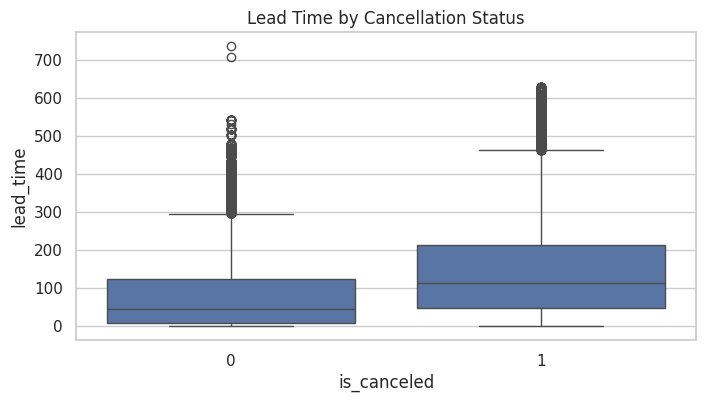

,lead_time_group,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0-7 days,19746,1902,0.096,0.092,0.101
1,8-30 days,18960,5283,0.279,0.272,0.285
2,31-90 days,29553,11141,0.377,0.371,0.383
3,91-180 days,26439,11821,0.447,0.441,0.453
4,181-365 days,21544,11947,0.555,0.548,0.561
5,>365 days,3148,2130,0.677,0.660,0.693


,hotel,lead_time_group,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,City Hotel,0-7 days,10808,1319,0.122,0.116,0.128
1,City Hotel,8-30 days,12554,3880,0.309,0.301,0.317
2,City Hotel,31-90 days,20797,8300,0.399,0.392,0.406
3,City Hotel,91-180 days,18223,8746,0.480,0.473,0.487
4,City Hotel,181-365 days,14244,8934,0.627,0.619,0.635
5,City Hotel,>365 days,2704,1923,0.711,0.694,0.728
6,Resort Hotel,0-7 days,8938,583,0.065,0.060,0.071
7,Resort Hotel,8-30 days,6406,1403,0.219,0.209,0.229
8,Resort Hotel,31-90 days,8756,2841,0.324,0.315,0.334
9,Resort Hotel,91-180 days,8216,3075,0.374,0.364,0.385


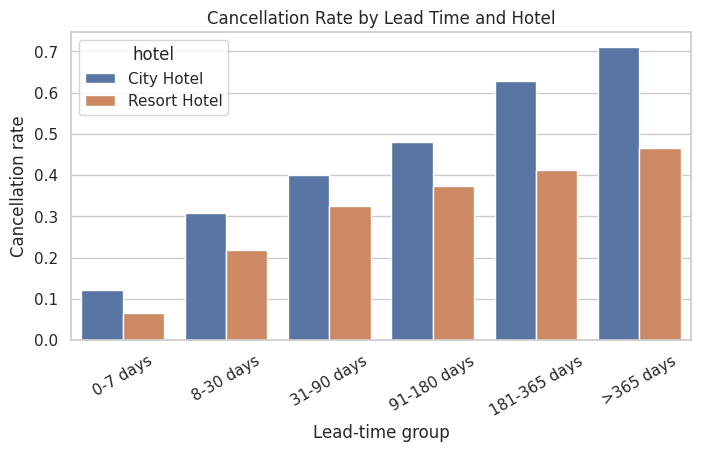

In [27]:
sns.boxplot(x="is_canceled", y="lead_time", data=df)
plt.title("Lead Time by Cancellation Status")
plt.show()

display(cancellation_summary(df, "lead_time_group", sort=False).round(3))

lead_by_hotel = cancellation_summary(df, ["hotel", "lead_time_group"], sort=False)
display(lead_by_hotel.round(3))
sns.barplot(data=lead_by_hotel, x="lead_time_group", y="cancellation_rate", hue="hotel")
plt.xticks(rotation=30)
plt.ylabel("Cancellation rate")
plt.xlabel("Lead-time group")
plt.title("Cancellation Rate by Lead Time and Hotel")
plt.show()

**Finding.** Across both hotels, the cancellation rate rises steadily with lead time: 9.6% (0-7 days), 27.9% (8-30), 37.7% (31-90), 44.7% (91-180), 55.5% (181-365) and 67.7% (>365 days). The same ordering holds in each hotel. The longest group is small (2,704 bookings in the City Hotel and 444 in the Resort Hotel), so its rates are less precise. Lead time is known at reservation time, which makes it a strong candidate predictor.

### 8.4 Cancellation over time

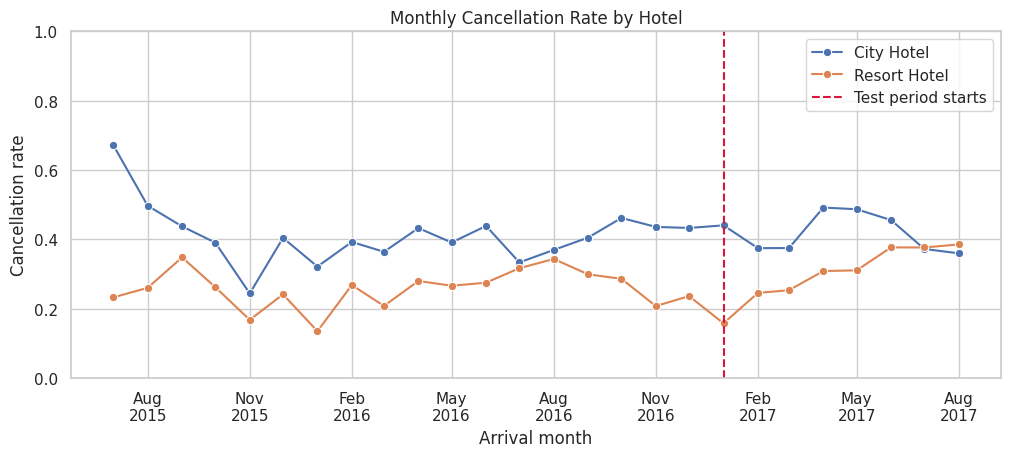

In [28]:
monthly = (df.assign(arrival_year_month=df["arrival_date"].dt.to_period("M").dt.to_timestamp())
             .groupby(["hotel", "arrival_year_month"])["is_canceled"]
             .agg(bookings="size", cancellation_rate="mean")
             .reset_index())

plt.figure(figsize=(12, 4.5))
sns.lineplot(data=monthly, x="arrival_year_month", y="cancellation_rate", hue="hotel", marker="o")
plt.axvline(pd.Timestamp("2017-01-01"), color="crimson", linestyle="--", label="Test period starts")
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
plt.ylim(0, 1)
plt.xlabel("Arrival month")
plt.ylabel("Cancellation rate")
plt.title("Monthly Cancellation Rate by Hotel")
plt.legend()
plt.show()

**Finding.** Cancellation rates change over time and the two hotels do not move together. The City Hotel starts very high in July 2015 (about 0.67), falls to about 0.25 by November 2015, then fluctuates roughly between 0.3 and 0.5 without a sustained trend. The Resort Hotel is lowest in winter and highest in summer in every year, so part of its rise during 2017 is seasonal; 8.10 compares the same months of 2016 and 2017 to separate seasonality from drift. Whether this drift makes a random split overstate performance is research question 2 and is tested in Phase 2.

### 8.5 Cancellation by market segment

,market_segment,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Groups,19811,12097,0.611,0.604,0.617
1,Online TA,56477,20739,0.367,0.363,0.371
2,Offline TA/TO,24219,8311,0.343,0.337,0.349
3,Aviation,237,52,0.219,0.171,0.276
4,Corporate,5295,992,0.187,0.177,0.198
5,Direct,12606,1934,0.153,0.147,0.160
6,Complementary,743,97,0.131,0.108,0.157


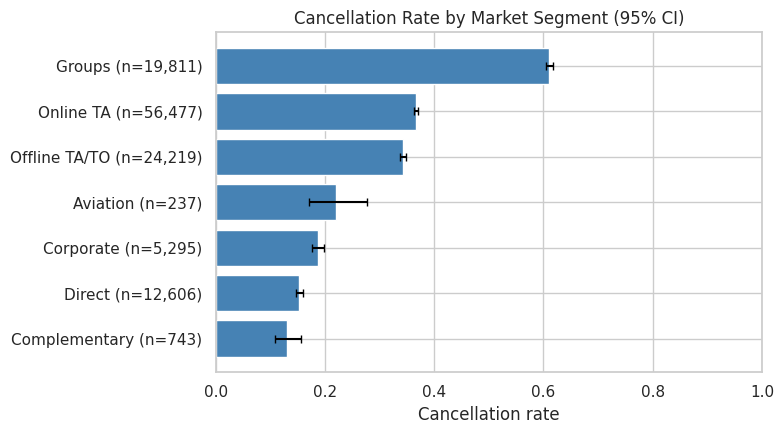

In [29]:
segment_rates = cancellation_summary(df, "market_segment", min_bookings=30)
display(segment_rates.round(3))
plot_rates(segment_rates, "market_segment", "Cancellation Rate by Market Segment (95% CI)")

**Finding.** Groups cancel at 61.1% (n=19,811; 16.6% of all bookings), far above the 37.0% overall rate. Online TA (36.7%, n=56,477) and Offline TA/TO (34.3%, n=24,219) are close to the average. The other segments are lower: Aviation 21.9% (n=237), Corporate 18.7% (n=5,295), Direct 15.3% (n=12,606), Complementary 13.1% (n=743). Online TA contributes the most cancellations in absolute terms (20,739), but Groups is the only segment with a markedly elevated rate. "Undefined" (2 bookings) is excluded from the chart.

### 8.6 Lead time and market segment by hotel

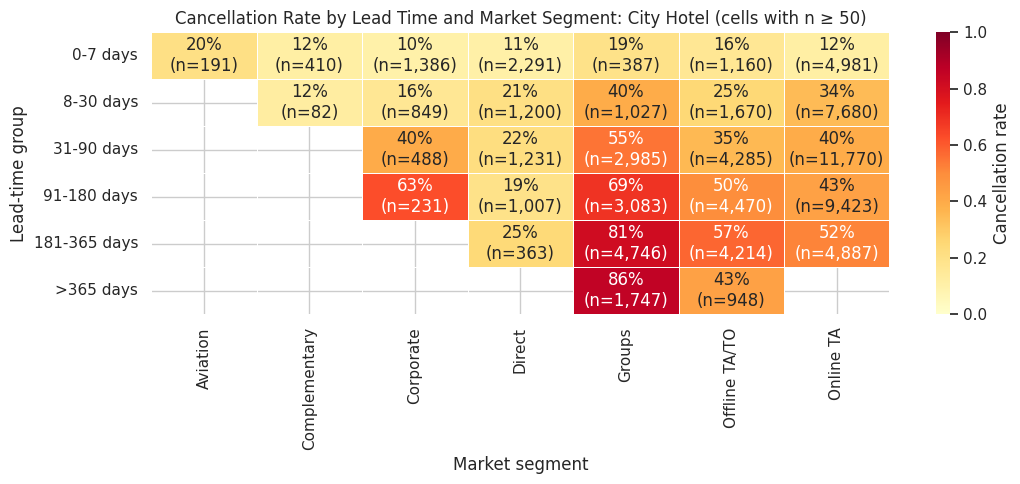

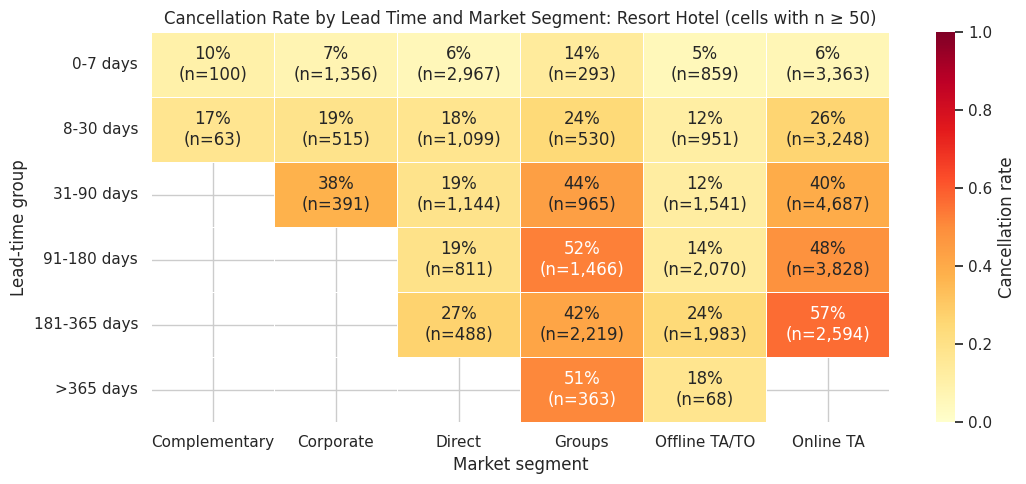

In [30]:
for hotel in ["City Hotel", "Resort Hotel"]:
    data = df[df["hotel"] == hotel]
    rate = data.pivot_table(index="lead_time_group", columns="market_segment",
                            values="is_canceled", aggfunc="mean", observed=False)
    count = data.pivot_table(index="lead_time_group", columns="market_segment",
                             values="is_canceled", aggfunc="size", observed=False).fillna(0)

    keep = (count >= 50).any()                 # drop segments with no cell of at least 50 bookings
    rate, count = rate.loc[:, keep], count.loc[:, keep]
    annotation = rate.apply(lambda col: [f"{r:.0%}\n(n={int(n):,})" if n >= 50 else ""
                                         for r, n in zip(col, count[col.name])])

    plt.figure(figsize=(11, 5))
    sns.heatmap(rate, mask=(count < 50), annot=annotation, fmt="", cmap="YlOrRd",
                vmin=0, vmax=1, linewidths=0.5, cbar_kws={"label": "Cancellation rate"})
    plt.title(f"Cancellation Rate by Lead Time and Market Segment: {hotel} (cells with n ≥ 50)")
    plt.xlabel("Market segment")
    plt.ylabel("Lead-time group")
    plt.tight_layout()
    plt.show()

**Finding.** The effect of lead time depends on the segment. In the City Hotel, Group bookings rise from 19% (0-7 days, n=387) to 40% (8-30 days, n=1,027), 55% (31-90 days, n=2,985), 69% (91-180 days, n=3,083), 81% (181-365 days, n=4,746) and 86% (>365 days, n=1,747). Direct bookings stay between 11% and 25% in every lead-time group. Resort Hotel patterns have the same direction at lower levels (for example, Groups at 181-365 days: 42%, n=2,219). Lead time and segment should therefore be modelled together, not as independent effects.

### 8.7 Fields requiring a definition and timing check: deposit type and parking

,deposit_type,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Non Refund,14587,14494,0.994,0.992,0.995
1,No Deposit,104641,29694,0.284,0.281,0.287
2,Refundable,162,36,0.222,0.165,0.292


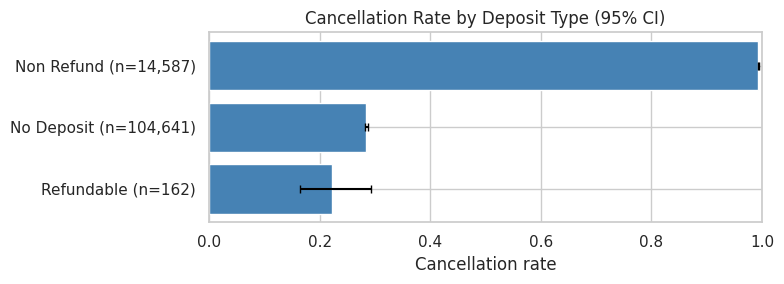

,required_car_parking_spaces,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,111974,44224,0.395,0.392,0.398
1,1,7383,0,0.000,0.000,0.001
2,2,28,0,0.000,0.000,0.121
3,3,3,0,0.000,0.000,0.562
4,8,2,0,0.000,0.000,0.658


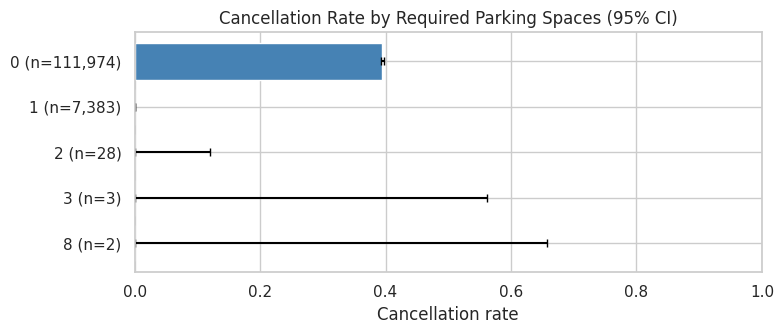

In [31]:
deposit_rates = cancellation_summary(df, "deposit_type")
display(deposit_rates.round(3))
plot_rates(deposit_rates, "deposit_type", "Cancellation Rate by Deposit Type (95% CI)")

parking_rates = cancellation_summary(df, "required_car_parking_spaces", sort=False)
display(parking_rates.round(3))
plot_rates(parking_rates, "required_car_parking_spaces", "Cancellation Rate by Required Parking Spaces (95% CI)")

### 8.7b Where do Non Refund bookings sit?
**What and why.** A near-100% cancellation rate under a refund-penalty policy is implausible, so we check whether it is concentrated in specific segments, hotels or countries.

In [32]:
nr = df[df["deposit_type"] == "Non Refund"]

display(pd.DataFrame({
    "non_refund_bookings": nr["market_segment"].value_counts(),
    "share_of_non_refund_%": nr["market_segment"].value_counts(normalize=True) * 100,
    "cancel_rate": nr.groupby("market_segment")["is_canceled"].mean(),
}).round(3))

display(nr.groupby("hotel")["is_canceled"].agg(bookings="size", cancel_rate="mean").round(3))
display(nr.groupby("arrival_date_year")["is_canceled"].agg(bookings="size", cancel_rate="mean").round(3))
print("Share of Non Refund bookings from Portugal:", round((nr["country"] == "PRT").mean(), 3))

,non_refund_bookings,share_of_non_refund_%,cancel_rate
market_segment,,,
Corporate,334,2.290,0.934
Direct,19,0.130,0.842
Groups,9172,62.878,0.993
Offline TA/TO,5006,34.318,0.999
Online TA,56,0.384,0.946


,bookings,cancel_rate
hotel,,
City Hotel,12868,0.998
Resort Hotel,1719,0.960


,bookings,cancel_rate
arrival_date_year,,
2015,3667,0.998
2016,6794,0.989
2017,4126,0.998


Share of Non Refund bookings from Portugal: 0.972


**Findings.** Non Refund bookings cancel at nearly 100% in every group, so the pattern is systematic rather than specific to one segment. Groups make up 62.9% of them (9,172; 99.3% cancelled) and Offline TA/TO 34.3% (5,006; 99.9%). 88.2% are in the City Hotel (12,868; 99.8% cancelled; Resort 96.0%), the rate is stable across years (99.8%, 98.9%, 99.8% for 2015-2017), and 97.2% are Portuguese bookings. This looks like a recording or policy artefact tied to Portuguese group and agent bookings rather than genuine guest behaviour. It cannot be confirmed from the data, so Phase 2 tests models with and without `deposit_type`.

### 8.8 Special requests and guest history

,total_of_special_requests,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,70318,33556,0.477,0.474,0.481
1,1,33226,7318,0.220,0.216,0.225
2,2,12969,2866,0.221,0.214,0.228
3,3,2497,446,0.179,0.164,0.194
4,4,340,36,0.106,0.077,0.143
5,5,40,2,0.050,0.014,0.165


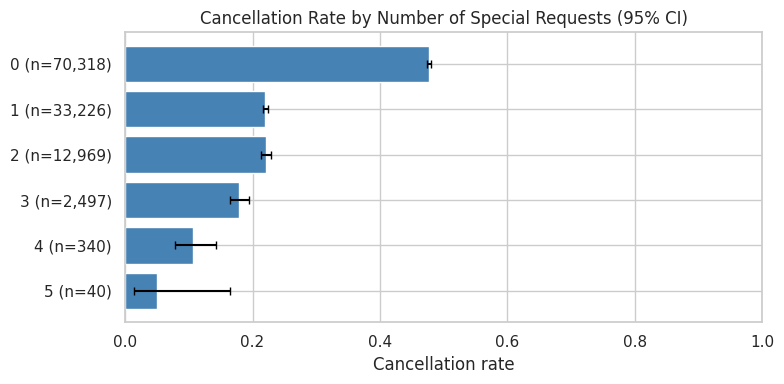

,is_repeated_guest,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,New guest,115580,43672,0.378,0.375,0.381
1,Repeat guest,3810,552,0.145,0.134,0.156


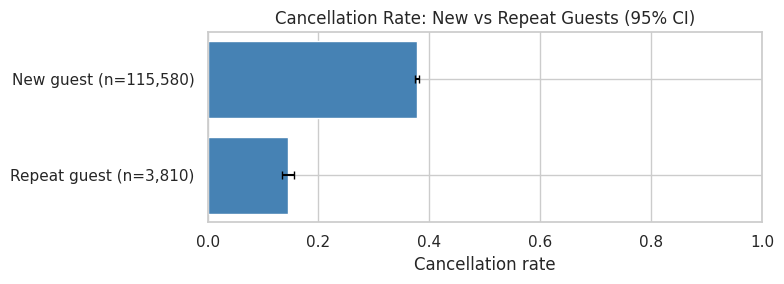

In [33]:
request_rates = cancellation_summary(df, "total_of_special_requests", sort=False)
display(request_rates.round(3))
plot_rates(request_rates, "total_of_special_requests", "Cancellation Rate by Number of Special Requests (95% CI)")

repeat_rates = cancellation_summary(df, "is_repeated_guest", sort=False)
repeat_rates["is_repeated_guest"] = repeat_rates["is_repeated_guest"].map({0: "New guest", 1: "Repeat guest"})
display(repeat_rates.round(3))
plot_rates(repeat_rates, "is_repeated_guest", "Cancellation Rate: New vs Repeat Guests (95% CI)")

**Findings.**
- **Special requests:** bookings with no request cancel at 47.7% (n=70,318). The rate falls to 22.0% with one request (n=33,226), 22.1% with two (n=12,969), 17.9% with three (n=2,497), 10.6% with four (n=340) and 5.0% with five (n=40). Requests can be added after booking, so this field is ambiguous, and the strong association may partly reflect later recording.
- **Guest history:** repeat guests cancel at 14.5% (n=3,810) against 37.8% for new guests (n=115,580). Repeat guests are only 3.2% of bookings, so this signal covers few reservations.

### 8.9 Customer type and country

,customer_type,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Transient,89613,36514,0.407,0.404,0.411
1,Contract,4076,1262,0.310,0.296,0.324
2,Transient-Party,25124,6389,0.254,0.249,0.260
3,Group,577,59,0.102,0.080,0.130


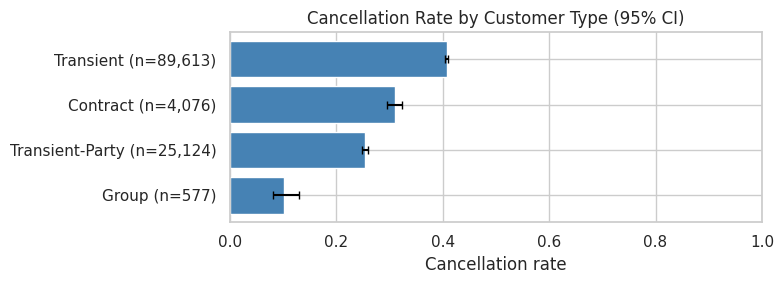

,country,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,PRT,48590,27519,0.566,0.562,0.571
1,GBR,12129,2453,0.202,0.195,0.209
2,FRA,10415,1934,0.186,0.178,0.193
3,ESP,8568,2177,0.254,0.245,0.263
4,DEU,7287,1218,0.167,0.159,0.176
5,ITA,3766,1333,0.354,0.339,0.369
6,IRL,3375,832,0.247,0.232,0.261
7,BEL,2342,474,0.202,0.187,0.219
8,BRA,2224,830,0.373,0.353,0.394
9,NLD,2104,387,0.184,0.168,0.201


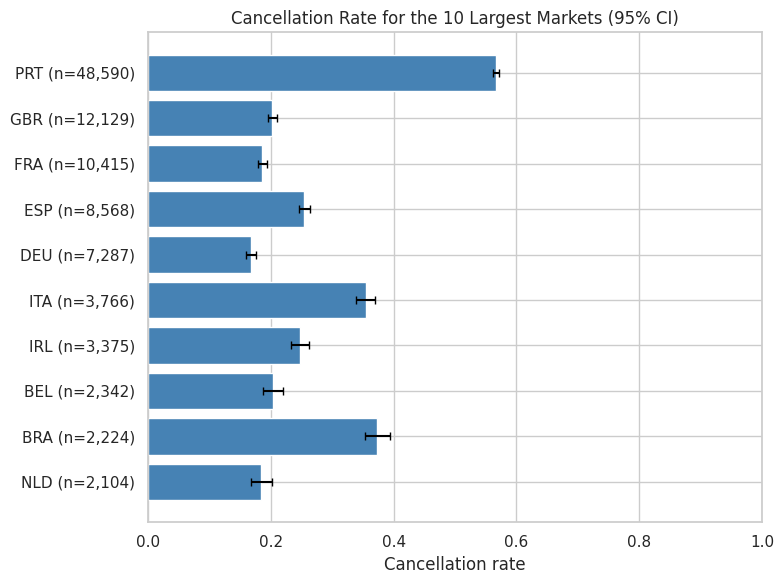

In [34]:
customer_rates = cancellation_summary(df, "customer_type")
display(customer_rates.round(3))
plot_rates(customer_rates, "customer_type", "Cancellation Rate by Customer Type (95% CI)")

top_countries = df["country"].value_counts().head(10).index
country_rates = cancellation_summary(df[df["country"].isin(top_countries)], "country", sort=False)
country_rates = country_rates.sort_values("bookings", ascending=False).reset_index(drop=True)
display(country_rates.round(3))
plot_rates(country_rates, "country", "Cancellation Rate for the 10 Largest Markets (95% CI)")

**Findings.**
- **Customer type:** Transient bookings are 75.1% of the data and cancel at 40.7% (n=89,613). Contract cancels at 31.0% (n=4,076), Transient-Party at 25.4% (n=25,124) and Group at 10.2% (n=577). `customer_type` = Group (10.2%) and `market_segment` = Groups (61.1%) describe different things, so both are kept.
- **Country:** Portugal (PRT) is 40.7% of bookings and cancels at 56.6% (n=48,590). Other large markets are lower: GBR 20.2%, FRA 18.6%, DEU 16.7%, ESP 25.4%, IRL 24.7%, BEL 20.2%, NLD 18.4%. ITA (35.4%) and BRA (37.3%) are higher.
- **Interpretation.** Domestic guests cancel far more often than international guests. 8.9b checks whether this overlaps with the Groups segment and Non Refund deposits before treating country as an independent driver. These are associations, not causal effects.

### 8.9b Overlap of country, segment and deposit type

In [35]:
df["is_prt"] = np.where(df["country"] == "PRT", "Portugal", "Other countries")

display(cancellation_summary(df, ["is_prt", "market_segment"], min_bookings=100).round(3))
display(cancellation_summary(df, ["is_prt", "deposit_type"], min_bookings=100).round(3))

,is_prt,market_segment,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Portugal,Groups,13893,11674,0.840,0.834,0.846
1,Portugal,Offline TA/TO,11985,8121,0.678,0.669,0.686
2,Portugal,Online TA,11982,5427,0.453,0.444,0.462
3,Portugal,Aviation,105,41,0.390,0.303,0.486
4,Other countries,Online TA,44495,15312,0.344,0.340,0.349
5,Portugal,Corporate,4108,958,0.233,0.221,0.246
6,Portugal,Direct,5850,1207,0.206,0.196,0.217
7,Portugal,Complementary,665,89,0.134,0.110,0.162
8,Other countries,Direct,6756,727,0.108,0.100,0.115
9,Other countries,Aviation,132,11,0.083,0.047,0.143


,is_prt,deposit_type,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Portugal,Non Refund,14176,14140,0.997,0.996,0.998
1,Other countries,Non Refund,411,354,0.861,0.825,0.891
2,Portugal,No Deposit,34366,13356,0.389,0.383,0.394
3,Other countries,No Deposit,70275,16338,0.232,0.229,0.236
4,Other countries,Refundable,114,13,0.114,0.068,0.185


**Finding.** The Portuguese effect is not only a mix effect. Within every segment, Portuguese bookings cancel more: Groups 84.0% against 7.1% for other countries, Offline TA/TO 67.8% against 1.6%, Online TA 45.3% against 34.4%, Corporate 23.3% against 2.9% and Direct 20.6% against 10.8%. Holding deposit type fixed shows the same: No Deposit 38.9% against 23.2%. The country gap is largest in Groups and Offline TA/TO, so country, segment and deposit type interact. Phase 2 should include interactions or tree models, and Phase 2 should check whether the Portuguese Groups / Offline TA/TO / Non Refund cluster is the same set of bookings.

### 8.10 ADR Distribution

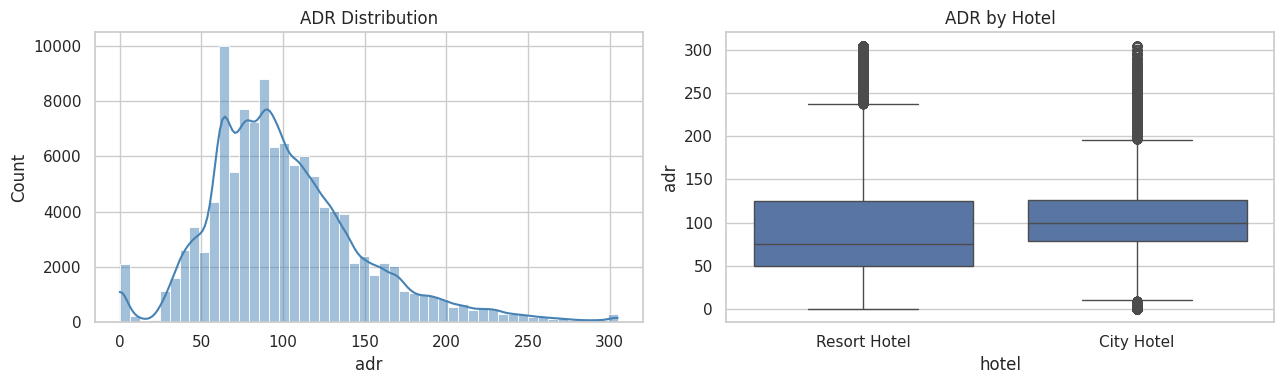

,mean,median
hotel,,
City Hotel,105.23,99.9
Resort Hotel,94.81,75.0


,high_adr,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,83077,29987,0.361,0.358,0.364
1,1,36313,14237,0.392,0.387,0.397


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["adr"], bins=50, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("ADR Distribution")
sns.boxplot(x="hotel", y="adr", data=df, ax=axes[1])
axes[1].set_title("ADR by Hotel")
plt.tight_layout()
plt.show()

display(df.groupby("hotel")["adr"].agg(["mean", "median"]).round(2))
display(cancellation_summary(df, "high_adr", sort=False).round(3))

**Finding.** ADR is right-skewed with a long upper tail. The City Hotel's median ADR is about 100 against about 75 for the Resort Hotel. About 2,000 bookings have ADR = 0 (likely complimentary or internal stays; they are retained, and Phase 2 tests sensitivity to them), and the small bump at 305 is the 99.9th-percentile cap from 4.3. Price level on its own shows only a weak association with cancellation (36.1% vs 39.2% for the two `high_adr` groups). ADR may matter more in combination with other fields, and it carries more revenue at risk per cancellation, which is relevant for the cost analysis in Phase 2.

### 8.11 Same-month comparison and drift (2016 vs 2017)
**What and why.** The test period covers January to August only, so seasonality must be removed before calling a change "drift". Only January to August of 2016 and 2017 are compared.

,hotel,arrival_date_year,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,City Hotel,2016,24450,9461,0.387,0.381,0.393
1,City Hotel,2017,27508,11691,0.425,0.419,0.431
2,Resort Hotel,2016,12346,3306,0.268,0.260,0.276
3,Resort Hotel,2017,13179,4054,0.308,0.300,0.316


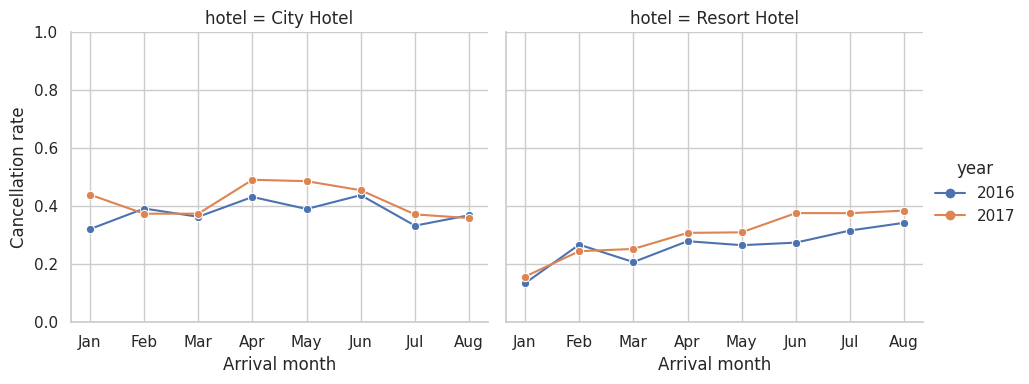

arrival_date_year,2016,2017
cancellation_rate,0.347,0.387
mean_lead_time,92.630,109.259
median_adr,91.550,107.100
share_high_adr,0.282,0.409
share_domestic,0.417,0.319
mean_total_nights,3.366,3.575
share_family,0.087,0.092


market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA
arrival_date_year,,,,,,,
2016,0.002,0.006,0.047,0.105,0.131,0.225,0.484
2017,0.003,0.005,0.038,0.114,0.144,0.139,0.557


deposit_type,No Deposit,Non Refund,Refundable
arrival_date_year,,,
2016,0.878,0.119,0.003
2017,0.898,0.101,0.001


In [37]:
same = df[df["arrival_date_month"].isin(month_order[:8]) & df["arrival_date_year"].isin([2016, 2017])].copy()

yoy = (same.groupby(["hotel", "arrival_date_year"], observed=True)["is_canceled"]
           .agg(bookings="size", cancellations="sum").reset_index())
yoy["cancellation_rate"] = yoy["cancellations"] / yoy["bookings"]
yoy["ci_low"], yoy["ci_high"] = wilson_interval(yoy["cancellations"], yoy["bookings"])
display(yoy.round(3))

m = (same.groupby(["hotel", "arrival_date_year", "arrival_date_month"], observed=True)["is_canceled"]
         .mean().reset_index())
m["month_no"] = m["arrival_date_month"].astype(str).map(month_number)
m["year"] = m["arrival_date_year"].astype(str)
g = sns.relplot(data=m, x="month_no", y="is_canceled", hue="year", col="hotel",
                kind="line", marker="o", height=4, aspect=1.2)
g.set(xticks=range(1, 9), xticklabels=[x[:3] for x in month_order[:8]], ylim=(0, 1))
g.set_axis_labels("Arrival month", "Cancellation rate")
plt.show()

drift = same.groupby("arrival_date_year").agg(
    cancellation_rate=("is_canceled", "mean"), mean_lead_time=("lead_time", "mean"),
    median_adr=("adr", "median"), share_high_adr=("high_adr", "mean"),
    share_domestic=("is_domestic", "mean"), mean_total_nights=("total_nights", "mean"),
    share_family=("is_family", "mean")).T.round(3)
display(drift)
display(pd.crosstab(same["arrival_date_year"], same["market_segment"], normalize="index").round(3))
display(pd.crosstab(same["arrival_date_year"], same["deposit_type"], normalize="index").round(3))

**Findings.** The cancellation rate increased in both hotels despite changes in booking composition. These changes may contribute to the difference, but the available comparisons do not establish their individual effects. This supports chronological validation in Phase 2

### 8.12 Association with the target (2015-2016 only)
**What and why.** Correlation and association are computed on the train/validation period only, so feature selection never uses 2017.

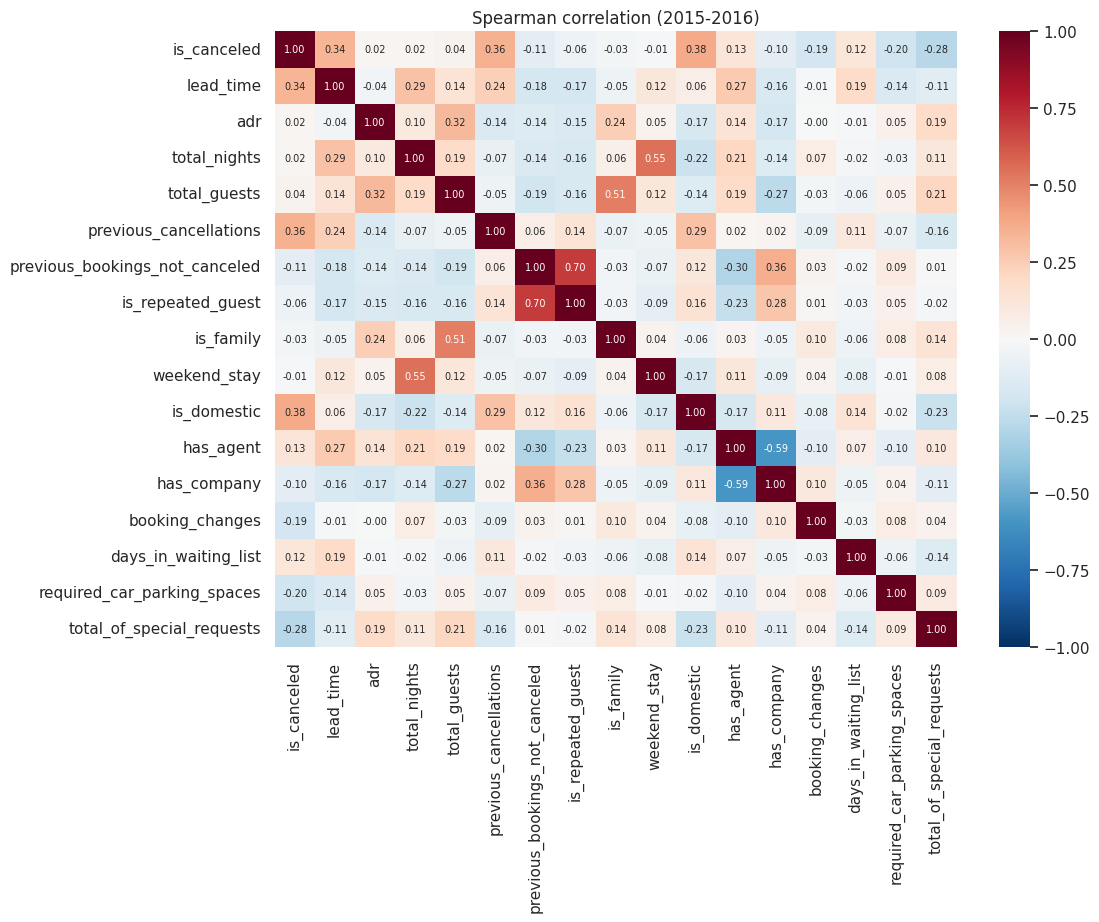

,spearman_with_target
is_domestic,0.377
previous_cancellations,0.357
lead_time,0.342
total_of_special_requests,-0.276
required_car_parking_spaces,-0.200
booking_changes,-0.185
has_agent,0.128
days_in_waiting_list,0.124
previous_bookings_not_canceled,-0.107
has_company,-0.103


,,feature_pair_corr
previous_bookings_not_canceled,is_repeated_guest,0.7


,cramers_v
deposit_type,0.514
country (top 10 + Other),0.385
market_segment,0.288
distribution_channel,0.175
hotel,0.148
customer_type,0.104
reserved_room_type,0.093
arrival_weekday,0.079
arrival_date_month,0.069
meal,0.054


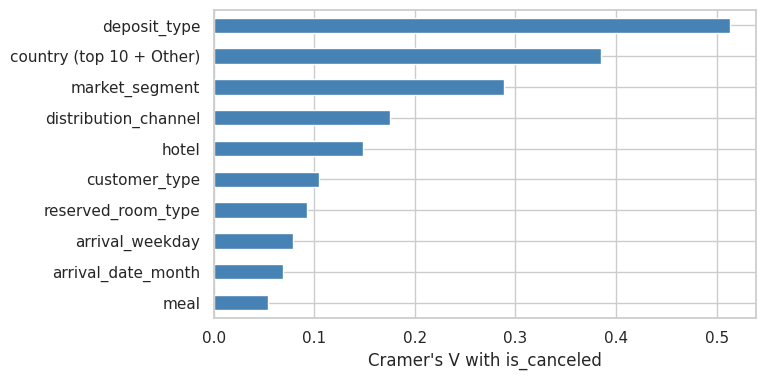

In [38]:
corr_cols = ["is_canceled", "lead_time", "adr", "total_nights", "total_guests", "previous_cancellations",
             "previous_bookings_not_canceled", "is_repeated_guest", "is_family", "weekend_stay",
             "is_domestic", "has_agent", "has_company", "booking_changes", "days_in_waiting_list",
             "required_car_parking_spaces", "total_of_special_requests"]
corr = train_df[corr_cols].corr(method="spearman")

plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Spearman correlation (2015-2016)")
plt.show()

display(corr["is_canceled"].drop("is_canceled").sort_values(key=abs, ascending=False)
        .round(3).to_frame("spearman_with_target"))

upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
display(upper[upper.abs() > 0.6].sort_values(key=abs, ascending=False).round(2).to_frame("feature_pair_corr"))

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    r, k = ct.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / min(kc - 1, rc - 1)))

top10 = train_df["country"].value_counts().head(10).index
cats = {c: train_df[c].astype(str) for c in ["hotel", "arrival_date_month", "arrival_weekday", "meal",
        "market_segment", "distribution_channel", "reserved_room_type", "customer_type", "deposit_type"]}
cats["country (top 10 + Other)"] = train_df["country"].where(train_df["country"].isin(top10), "Other")
cv = pd.Series({k: cramers_v(v, train_df["is_canceled"]) for k, v in cats.items()}).sort_values()
cv.plot.barh(figsize=(7, 4), color="steelblue")
display(cv.sort_values(ascending=False).round(3).to_frame("cramers_v"))
plt.xlabel("Cramer's V with is_canceled")
plt.show()

**Findings (2015-2016 only).**
Categorical associations (Cramér's V): deposit_type shows the strongest association with cancellation (V = [0.514]), followed by country (V = [0.385]) and market_segment (V = [0.288]). distribution_channel (V = [0.175]) and hotel (V = [0.148]) show weaker associations. customer_type, reserved_room_type, arrival_weekday, arrival_date_month and meal have relatively weak associations (V values below 0.11). deposit_type ranks first mainly because of the Non Refund pattern discussed in Section 8.7b, so Phase 2 will test it both with and without this feature.

### 8.13 Remaining variables
**What and why.** The variables not yet profiled are checked against cancellation using the same rate, n and 95% interval format.

,nights_group,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,715,35,0.049,0.035,0.067
1,1,21020,5271,0.251,0.245,0.257
2,2-3,54719,23514,0.430,0.426,0.434
3,4-7,37679,13525,0.359,0.354,0.364
4,8-14,4818,1636,0.340,0.326,0.353
5,15+,439,243,0.554,0.507,0.599


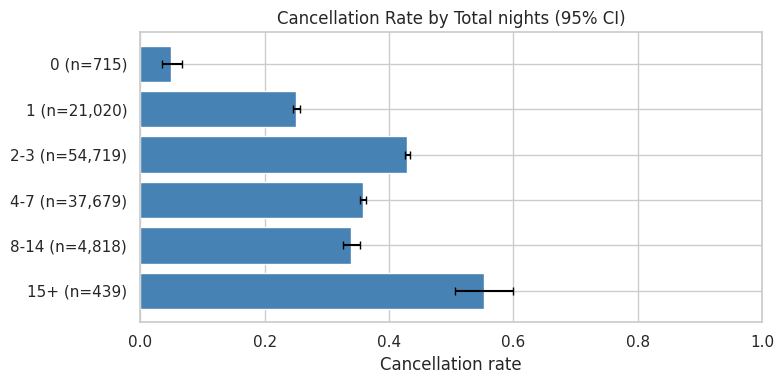

,meal,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,BB,92310,34510,0.374,0.371,0.377
1,FB,798,478,0.599,0.565,0.632
2,HB,14463,4984,0.345,0.337,0.352
3,SC,11819,4252,0.360,0.351,0.368


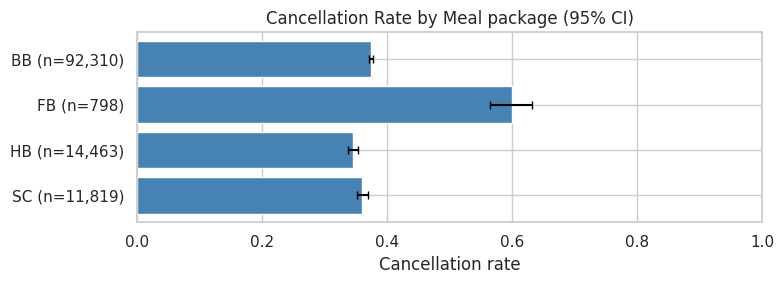

,distribution_channel,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Corporate,6677,1474,0.221,0.211,0.231
1,Direct,14645,2557,0.175,0.169,0.181
2,GDS,193,37,0.192,0.142,0.253
3,TA/TO,97870,40152,0.410,0.407,0.413


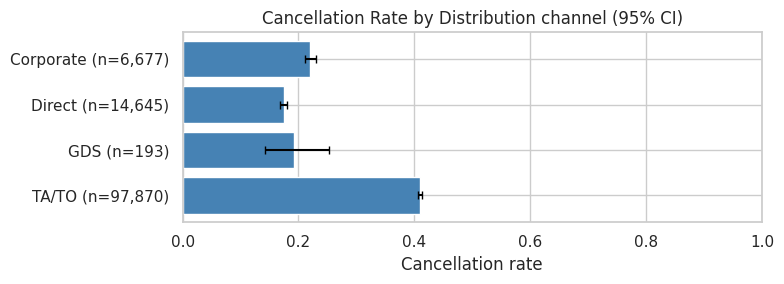

,reserved_room_type,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,A,85994,33630,0.391,0.388,0.394
1,B,1118,368,0.329,0.302,0.357
2,C,932,308,0.330,0.301,0.361
3,D,19201,6102,0.318,0.311,0.324
4,E,6535,1914,0.293,0.282,0.304
5,F,2897,880,0.304,0.287,0.321
6,G,2094,763,0.364,0.344,0.385
7,H,601,245,0.408,0.369,0.447


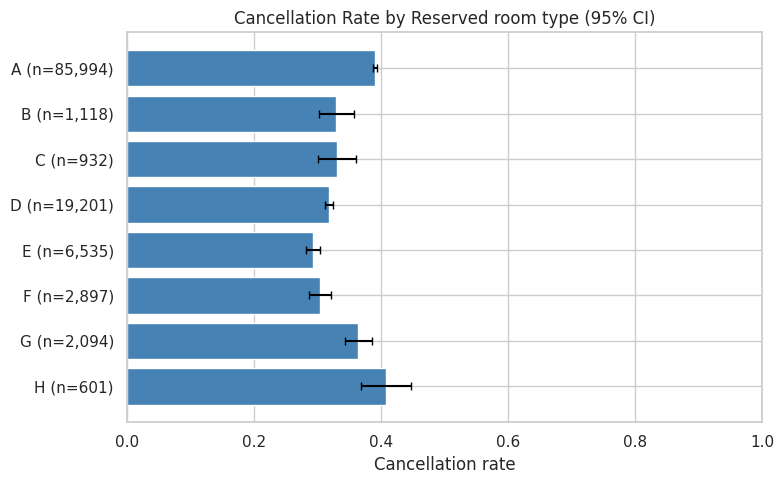

,booking_changes_group,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,101314,41391,0.409,0.406,0.412
1,1,12701,1807,0.142,0.136,0.148
2,2,3805,766,0.201,0.189,0.214
3,3+,1570,260,0.166,0.148,0.185


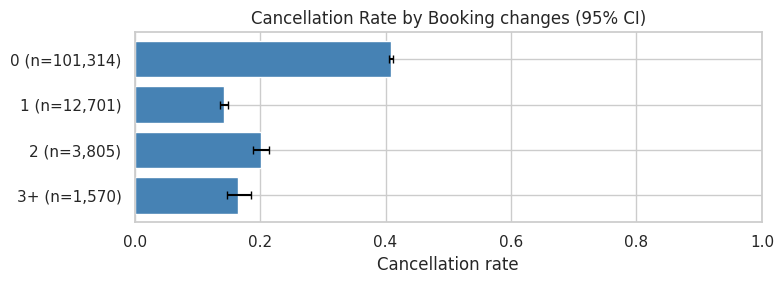

,has_previous_cancel,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,112906,38282,0.339,0.336,0.342
1,1,6484,5942,0.916,0.909,0.923


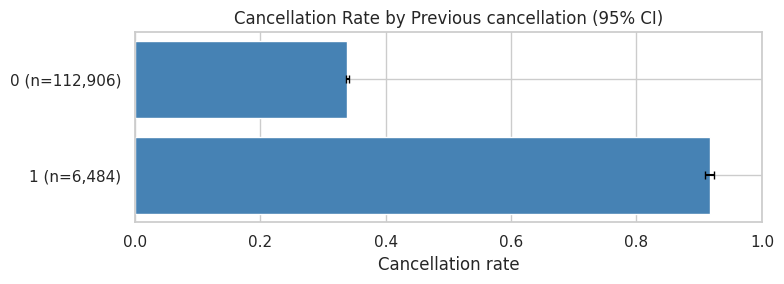

,was_waitlisted,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,115692,41865,0.362,0.359,0.365
1,1,3698,2359,0.638,0.622,0.653


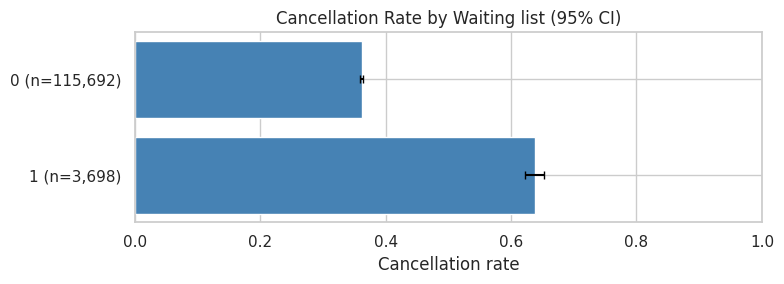

,arrival_weekday,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,Monday,18171,6195,0.341,0.334,0.348
1,Tuesday,13999,4600,0.329,0.321,0.336
2,Wednesday,16139,5831,0.361,0.354,0.369
3,Thursday,19254,7927,0.412,0.405,0.419
4,Friday,19631,7978,0.406,0.400,0.413
5,Saturday,18055,7129,0.395,0.388,0.402
6,Sunday,14141,4564,0.323,0.315,0.331


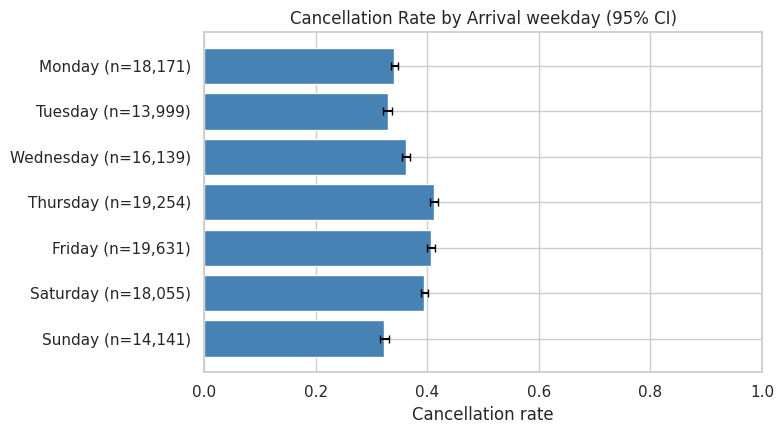

,has_agent,bookings,cancellations,cancellation_rate,ci_low,ci_high
0,0,16340,4030,0.247,0.240,0.253
1,1,103050,40194,0.390,0.387,0.393


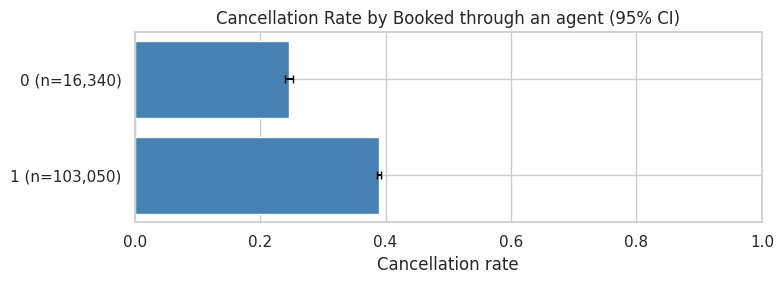

In [39]:
extra = [("nights_group", "Total nights"), ("meal", "Meal package"),
         ("distribution_channel", "Distribution channel"), ("reserved_room_type", "Reserved room type"),
         ("booking_changes_group", "Booking changes"), ("has_previous_cancel", "Previous cancellation"),
         ("was_waitlisted", "Waiting list"), ("arrival_weekday", "Arrival weekday"),
         ("has_agent", "Booked through an agent")]
for col, title in extra:
    s = cancellation_summary(df, col, min_bookings=30, sort=False)
    display(s.round(3))
    plot_rates(s, col, f"Cancellation Rate by {title} (95% CI)")

**Findings.**

- **Total nights:** Cancellation is lowest for bookings of 0 nights (4.9%) and 1 night (25.1%). It increases for longer stays, reaching 55.4% for bookings of 15 or more nights. However, this last group contains only 439 bookings.
- **Meal package:** Full Board (FB) has the highest cancellation rate (59.9%), compared with Bed & Breakfast (BB) at 37.4%, Self Catering (SC) at 36.0%, and Half Board (HB) at 34.5%. However, Full Board has a much smaller number of bookings (798).
- **Distribution channel:** Travel Agents/Tour Operators (TA/TO) have the highest cancellation rate (41.0%), followed by Corporate (22.1%), GDS (19.2%), and Direct bookings (17.5%). TA/TO also accounts for most bookings, making this pattern particularly relevant.

**Overall observation:** Cancellation patterns differ across stay length, meal package, and distribution channel. These variables may provide useful information for Phase 2 modelling, but their predictive contribution will be evaluated using the chronological validation setup.

In [40]:
prev = df[df["has_previous_cancel"] == 1]
print(prev["market_segment"].value_counts(normalize=True).round(3).head(4).to_dict())
print(prev["deposit_type"].value_counts(normalize=True).round(3).to_dict())
print("Portuguese share:", round((prev["country"] == "PRT").mean(), 3))

{'Groups': 0.516, 'Offline TA/TO': 0.259, 'Online TA': 0.095, 'Corporate': 0.089}
{'Non Refund': 0.562, 'No Deposit': 0.438}
Portuguese share: 0.951


## 9. Phase 1 Summary

Phase 1 successfully completed data cleaning, preprocessing, feature engineering, leakage analysis, and exploratory data analysis (EDA).

The dataset contains **119,390 hotel bookings**, with an overall cancellation rate of **37.04%**. Missing values and unusual ADR values were handled, while duplicate records were retained for analysis.

New features were created to describe booking behaviour, and a leakage audit separated reliable predictors from ambiguous and outcome-related variables.

EDA highlighted important cancellation patterns:
- City Hotel bookings have higher cancellation rates than Resort Hotel bookings.
- Longer lead times are associated with more cancellations.
- Group bookings and Portuguese bookings show higher cancellation rates.
- Cancellation patterns vary across booking channels, meal types, and stay lengths.
- Cancellation rates increased in both hotel types from 2016 to 2017.

Finally, the preprocessing pipeline was fitted using **2015–2016 data**, with **2017 reserved for testing** to support chronological validation.

**Phase 1 is complete.** Phase 2 will focus on model training, evaluation, comparison, and identifying the most useful predictors of hotel booking cancellations.

In [41]:
assert df.shape[0] == 119390 and int(df["is_canceled"].sum()) == 44224
assert set(df["split"].unique()) == {"train_val", "test"}
assert not {"reservation_status", "reservation_status_date", "assigned_room_type"} & set(df.columns)
print("Notebook executed top to bottom without errors.")

Notebook executed top to bottom without errors.


In [42]:
df.to_csv("hotel_bookings_cleaned.csv", index=False)
print("Saved hotel_bookings_cleaned.csv", df.shape)

Saved hotel_bookings_cleaned.csv (119390, 46)
